In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student_sleep_mental_health_2026.csv")
df.head()

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,1,21,Non-binary,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,False,True
1,2,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,True,True
2,3,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,True,True
3,4,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,False,True
4,5,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,False,True


In [3]:
df["gender"].value_counts()

gender
Female               1410
Male                 1406
Non-binary            110
Prefer not to say      74
Name: count, dtype: int64

In [4]:
def gender_fill_other(gen):
    if gen == "Female" or gen == "Male":
        return gen
    else:
        return "Other"

df["gender"] = df["gender"].apply(gender_fill_other)
df["gender"].value_counts()

gender
Female    1410
Male      1406
Other      184
Name: count, dtype: int64

In [5]:
df[["uses_sleep_app","feels_burned_out"]] = df[["uses_sleep_app","feels_burned_out"]].astype(int)
df.head()

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,1,21,Other,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,0,1
1,2,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,1,1
2,3,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,1,1
3,4,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,0,1
4,5,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,0,1


In [6]:
df.shape

(3000, 15)

In [7]:
df.columns

Index(['student_id', 'age', 'gender', 'education_level', 'avg_sleep_hours',
       'screen_time_hours', 'social_media_hours', 'study_hours_per_day',
       'exercise_hours_per_week', 'caffeine_drinks_per_day', 'stress_level',
       'anxiety_score', 'gpa', 'uses_sleep_app', 'feels_burned_out'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               3000 non-null   int64  
 1   age                      3000 non-null   int64  
 2   gender                   3000 non-null   object 
 3   education_level          3000 non-null   object 
 4   avg_sleep_hours          3000 non-null   float64
 5   screen_time_hours        3000 non-null   float64
 6   social_media_hours       3000 non-null   float64
 7   study_hours_per_day      3000 non-null   float64
 8   exercise_hours_per_week  3000 non-null   float64
 9   caffeine_drinks_per_day  3000 non-null   int64  
 10  stress_level             3000 non-null   int64  
 11  anxiety_score            3000 non-null   int64  
 12  gpa                      3000 non-null   float64
 13  uses_sleep_app           3000 non-null   int64  
 14  feels_burned_out        

In [9]:
df.isnull().sum()

student_id                 0
age                        0
gender                     0
education_level            0
avg_sleep_hours            0
screen_time_hours          0
social_media_hours         0
study_hours_per_day        0
exercise_hours_per_week    0
caffeine_drinks_per_day    0
stress_level               0
anxiety_score              0
gpa                        0
uses_sleep_app             0
feels_burned_out           0
dtype: int64

In [10]:
df.drop("student_id",axis=1,inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,19.445000,7.414067,6.494667,3.575033,3.235200,3.541900,1.778667,7.216667,7.152000,3.244487,0.342667,0.679667
std,2.924921,0.971279,2.165014,1.563631,1.405491,2.336889,1.341496,1.572433,1.994882,0.379404,0.474680,0.466682
min,14.000000,4.400000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.970000,0.000000,0.000000
25%,17.000000,6.800000,5.000000,2.500000,2.300000,1.800000,1.000000,6.000000,6.000000,2.980000,0.000000,0.000000
50%,19.000000,7.400000,6.500000,3.600000,3.200000,3.400000,2.000000,7.000000,7.000000,3.245000,0.000000,1.000000
75%,21.000000,8.100000,8.000000,4.600000,4.200000,5.100000,3.000000,8.000000,9.000000,3.510000,1.000000,1.000000
max,29.000000,10.900000,13.600000,9.000000,8.700000,11.300000,8.000000,10.000000,10.000000,4.000000,1.000000,1.000000


In [13]:
df["stress_level"].unique()

array([ 7,  8,  9, 10,  6,  5,  4,  3,  1,  2])

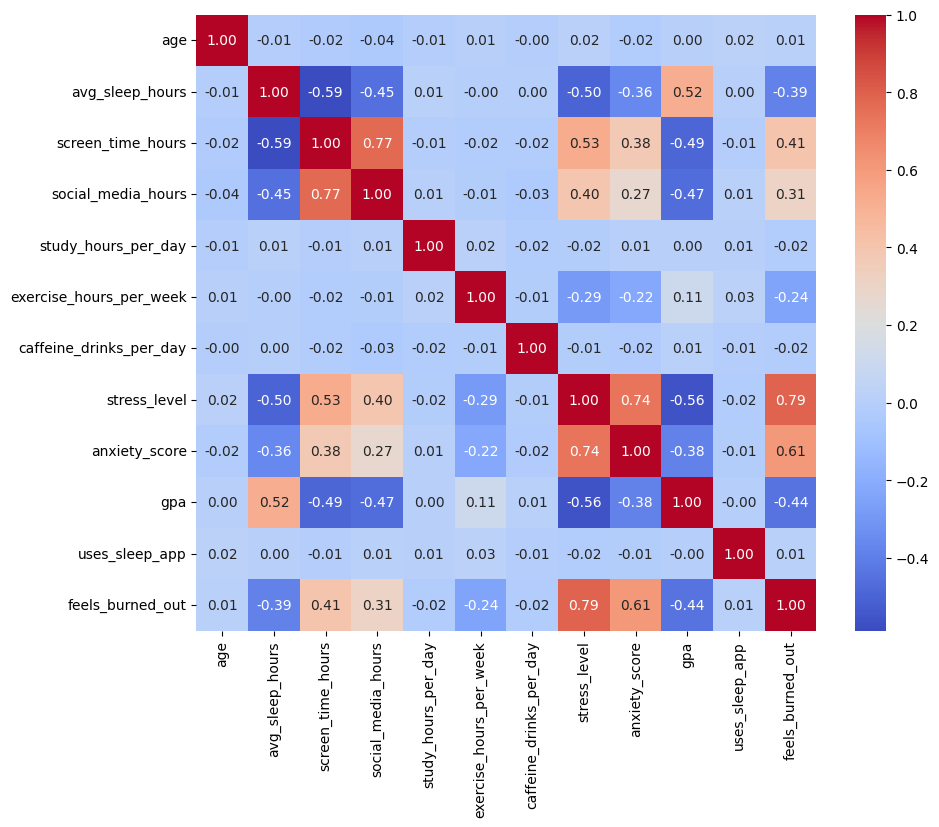

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [15]:
df.head()

,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,21,Other,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,0,1
1,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,1,1
2,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,1,1
3,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,0,1
4,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,0,1


In [16]:
cat_cols = df.select_dtypes("object").columns.tolist()
num_cols = df.select_dtypes("number").columns.tolist()

print(cat_cols)
print(num_cols)

['gender', 'education_level']
['age', 'avg_sleep_hours', 'screen_time_hours', 'social_media_hours', 'study_hours_per_day', 'exercise_hours_per_week', 'caffeine_drinks_per_day', 'stress_level', 'anxiety_score', 'gpa', 'uses_sleep_app', 'feels_burned_out']


In [17]:
from sklearn.model_selection import train_test_split

X = df.drop("stress_level",axis=1)
y = df["stress_level"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

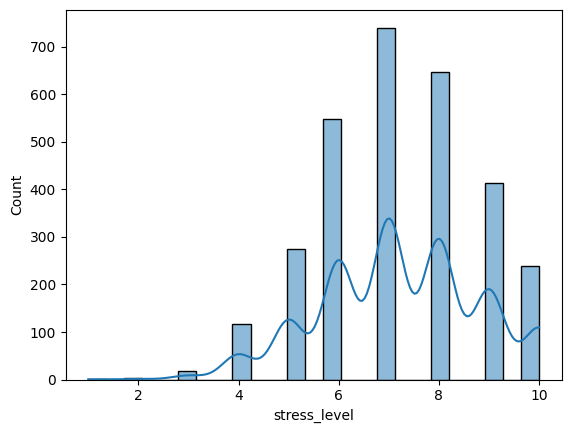

In [18]:
sns.histplot(df,x=num_cols.pop(7),bins=25,kde=True)
plt.show()

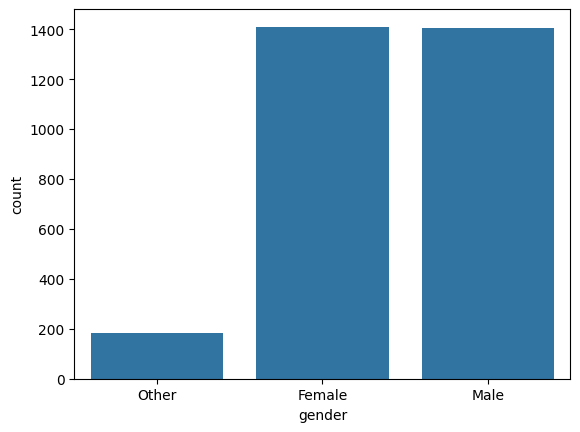

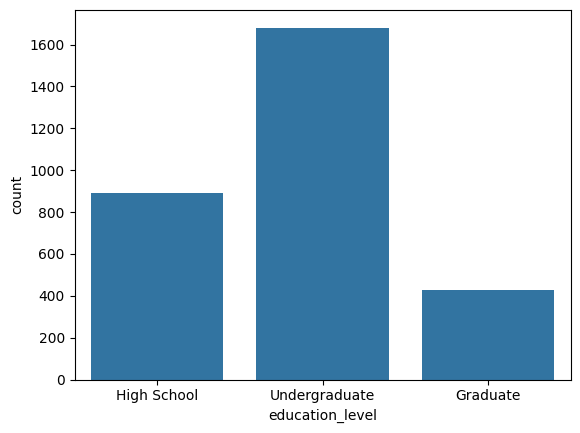

In [19]:
for i in cat_cols:
    sns.countplot(df,x=i)
    plt.show()

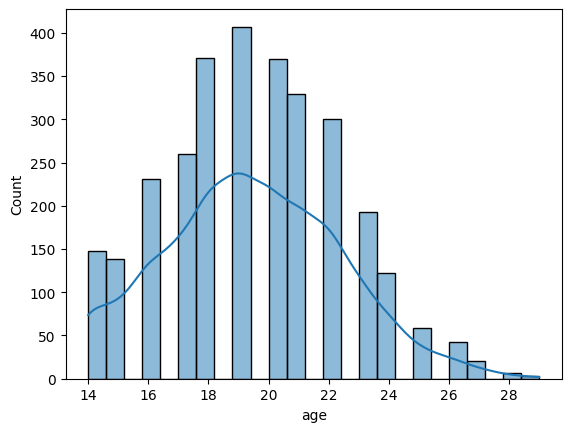

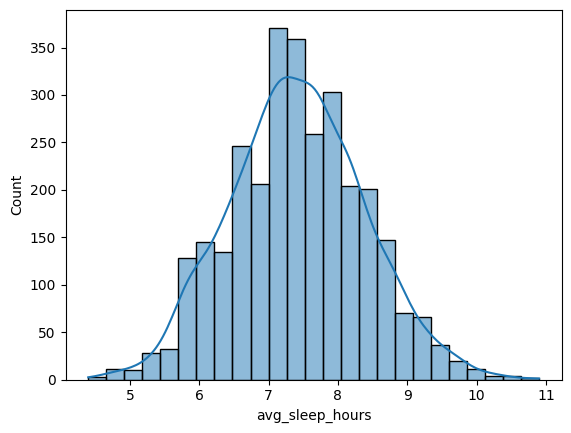

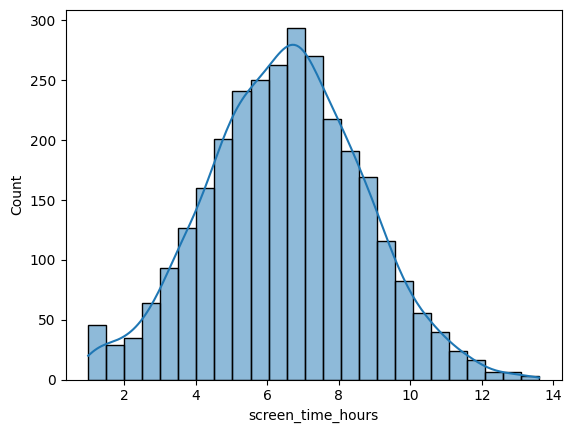

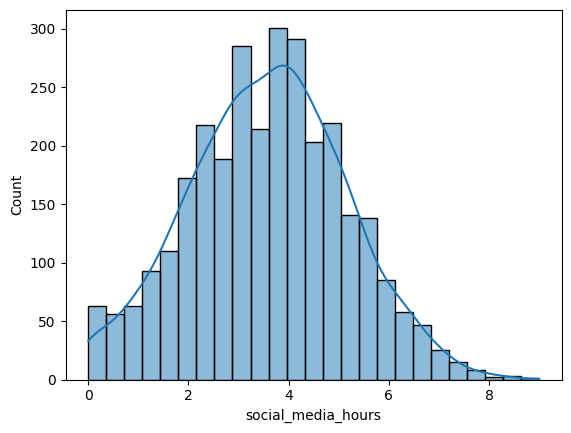

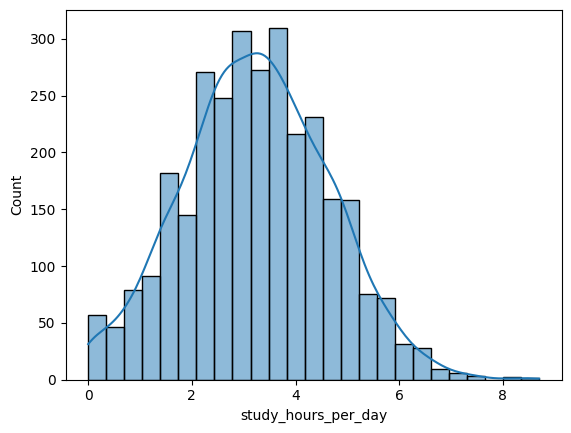

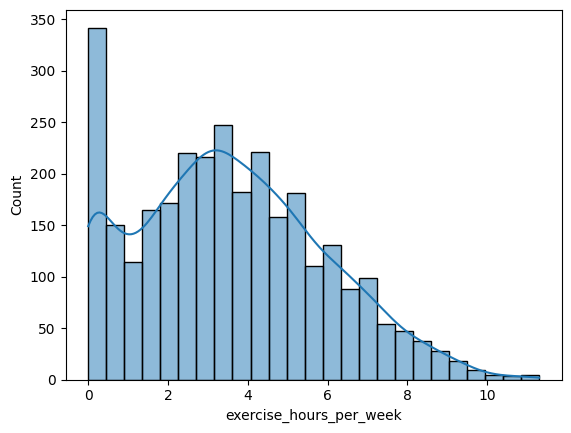

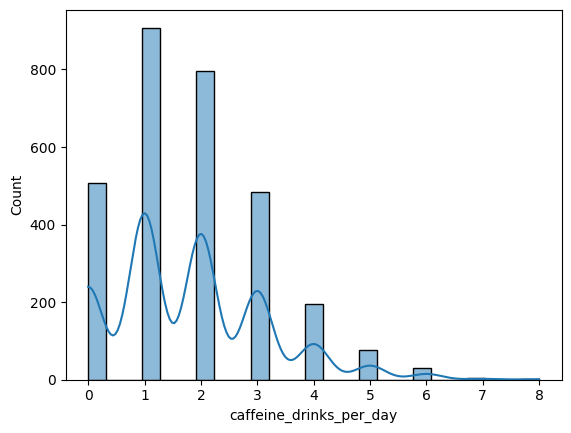

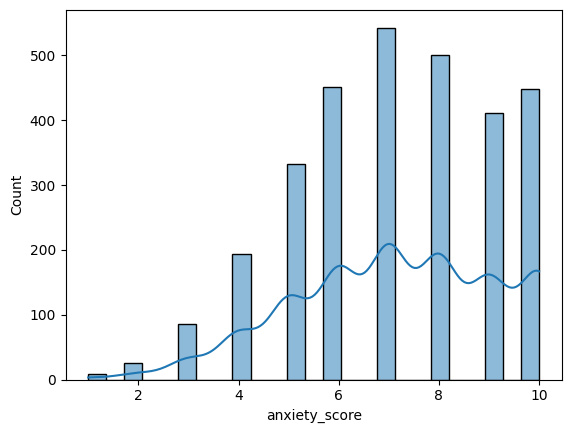

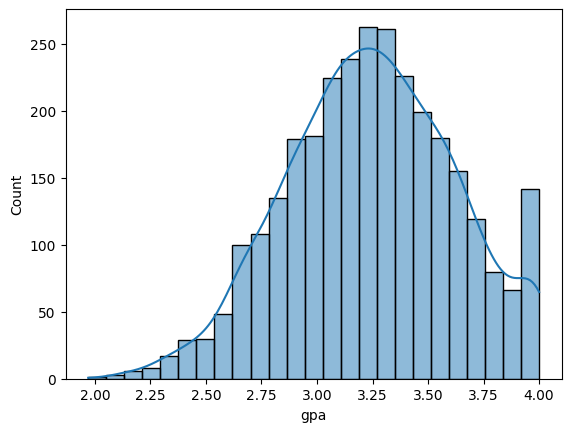

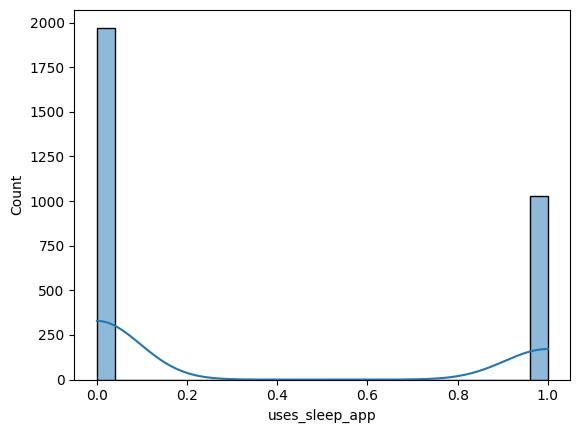

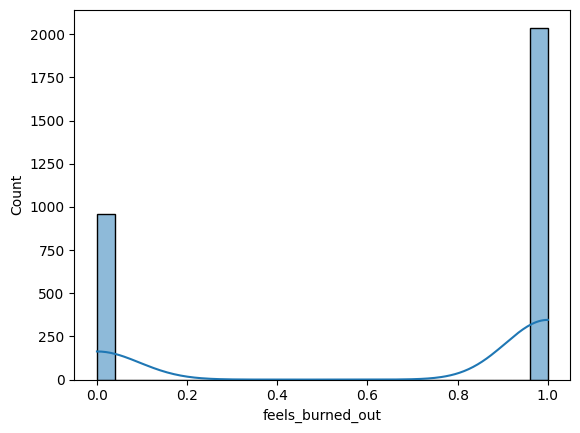

In [20]:
for i in num_cols:
    sns.histplot(df,x=i,bins=25,kde=True)
    plt.show()

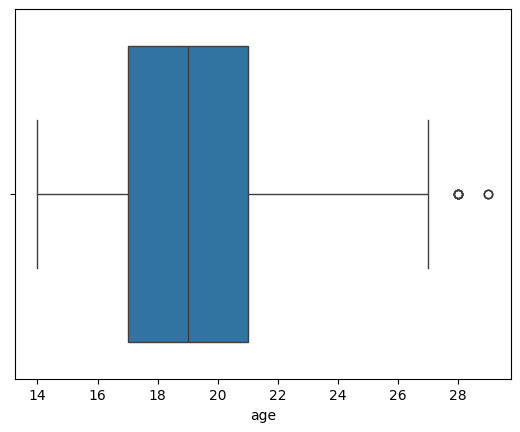

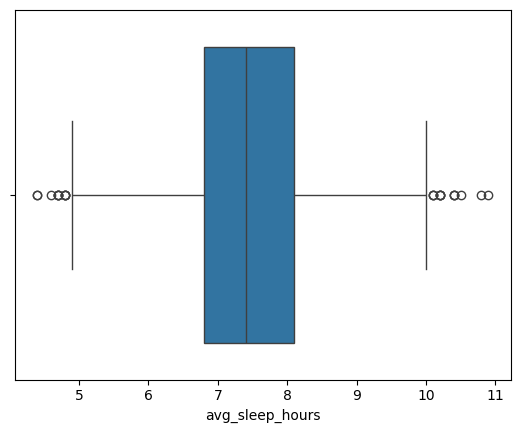

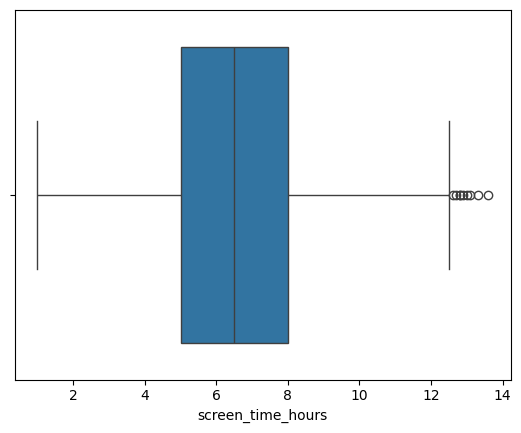

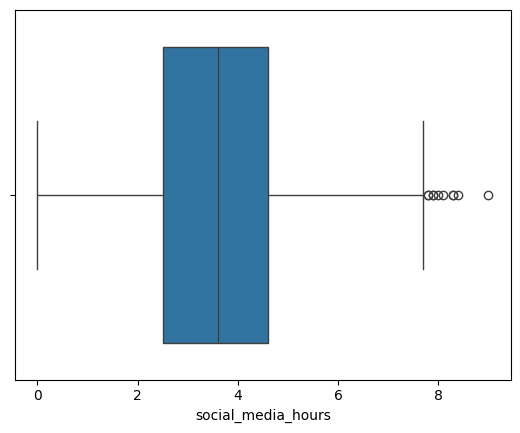

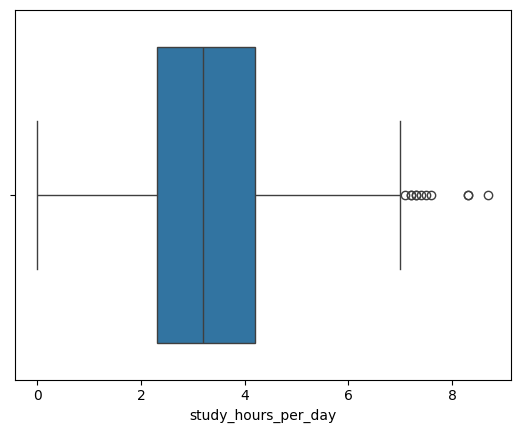

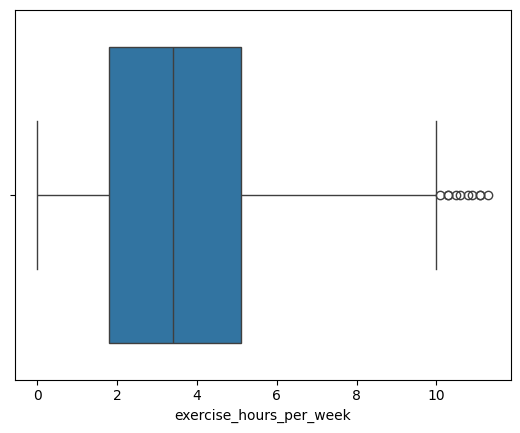

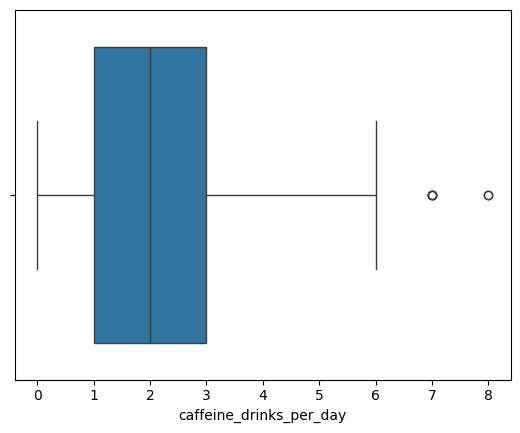

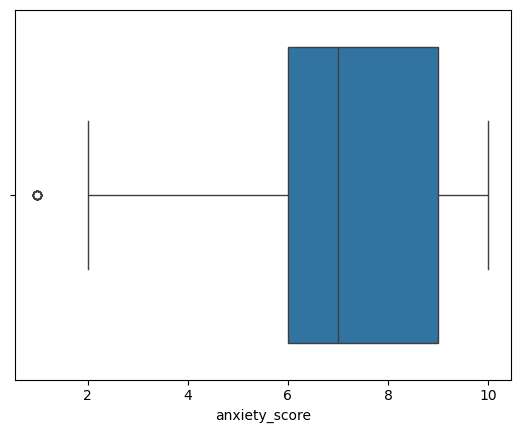

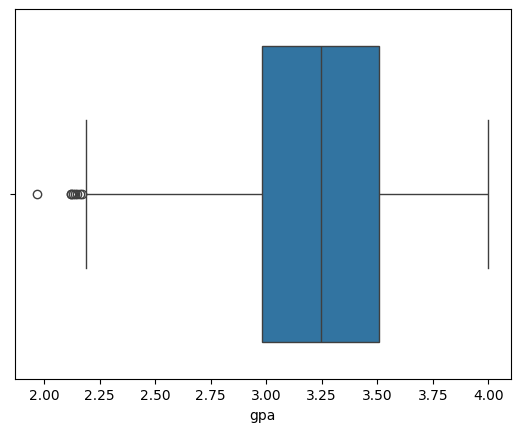

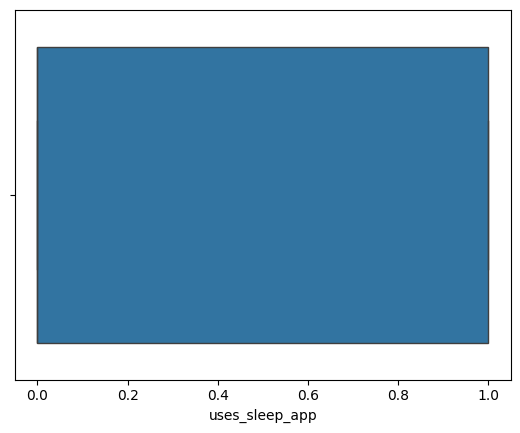

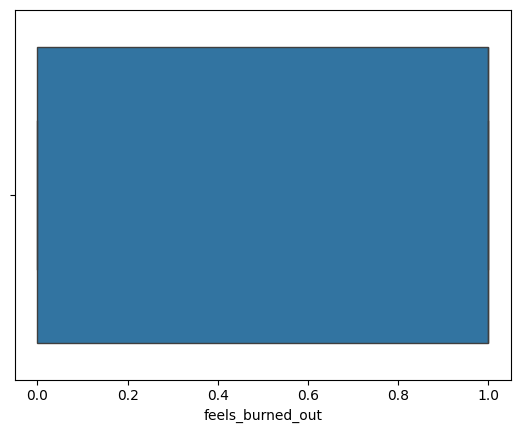

In [21]:
for i in num_cols:
    sns.boxplot(df,x=i)
    plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [23]:
preprocessor = ColumnTransformer([
    ("num",Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("skew",PowerTransformer(method="yeo-johnson")),
        ("scaler",StandardScaler())
    ]),num_cols),
    ("cat",Pipeline([
        ("impute",SimpleImputer(strategy="most_frequent")),
        ("encode",OneHotEncoder(handle_unknown="ignore"))
    ]),cat_cols)
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [24]:
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor ,AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

In [26]:
results = []
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1, max_iter=10000),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'K-Neighbors': KNeighborsRegressor(),
    'Support Vector Regressor': SVR(kernel='rbf'),
    "XGBoost": XGBRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
}

In [27]:
for name,model in models.items():
    model.fit(X_train_pre,y_train)
    y_pred = model.predict(X_test_pre)
    R2_score = r2_score(y_test,y_pred)
    MSE = mean_squared_error(y_test, y_pred)
    MAE = mean_absolute_error(y_test, y_pred)
    RMSE = np.sqrt(MSE)
    results.append({
        "Name":name,
        "R2_score":R2_score,
        "MSE":MSE,
        "MAE":MAE,
        "RMSE":RMSE
    })

results_df = pd.DataFrame(results)
results_df

,Name,R2_score,MSE,MAE,RMSE
0,Linear Regression,0.754754,0.540969,0.587360,0.735506
1,Ridge Regression,0.754767,0.540941,0.587321,0.735487
2,Lasso Regression,0.752756,0.545377,0.586375,0.738497
3,ElasticNet,0.755405,0.539534,0.581245,0.734530
4,Decision Tree,0.509631,1.081667,0.718333,1.040032
5,Random Forest,0.748367,0.555057,0.583983,0.745021
6,Extra Trees,0.745700,0.560941,0.587200,0.748960
7,Gradient Boosting,0.766918,0.514137,0.574070,0.717034
8,K-Neighbors,0.678034,0.710200,0.655000,0.842734
9,Support Vector Regressor,0.733977,0.586800,0.594545,0.766029


In [37]:
xg_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBRegressor(learning_rate=0.1,random_state=42))
])
xg_model.fit(X_train, y_train)
y_pred = xg_model.predict(X_test)
R2_score = r2_score(y_test,y_pred)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

print(R2_score)
print(MSE)
print(MAE)

0.744054913520813
0.5645694136619568
0.5881155729293823


In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}

In [32]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


c:\Users\Amir sohail\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_search.py:1137: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan]
  warnings.warn(


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': <scipy.stats....002B89E331490>, 'classifier__gamma': <scipy.stats....002B89E333020>, 'classifier__learning_rate': <scipy.stats....002B8997BB6B0>, 'classifier__max_depth': <scipy.stats....002B89E0432C0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the split

In [33]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.7028540917094453),
 'classifier__gamma': np.float64(0.30442783026010556),
 'classifier__learning_rate': np.float64(0.15932856652711375),
 'classifier__max_depth': 8,
 'classifier__min_child_weight': 8,
 'classifier__n_estimators': 420,
 'classifier__subsample': np.float64(0.8681795215389143)}

In [36]:
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)
R2_score = r2_score(y_test,y_pred)
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)

print(R2_score)
print(MSE)
print(MAE)

0.7228372097015381
0.6113719940185547
0.5984541773796082


In [38]:
import joblib

joblib.dump(xg_model, "model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']